**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

*   NOMBRE: Italo Javier Contreras Pérez
*   MATRÍCULA: A01841252

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [527]:
# Instalar las bibliotecas necesarias
!pip install category_encoders

In [528]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder

In [529]:
import warnings
warnings.filterwarnings('ignore')

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.

In [530]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [531]:
compu_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/MNA/1er trimestre/Ciencia y analitica de datos/semana 6/computer_prices.csv')

compu_df.head(5)

,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,...,storage_gb,storage_drive_count,display_type,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,12,...,1024,1,LED,0,750,Wi-Fi 6,5.1,11.00,36,1383.99
1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,...,512,1,OLED,120,0,Wi-Fi 6,5.3,2.03,12,2274.99
2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,8,...,512,2,LED,0,850,Wi-Fi 6,5.0,7.00,24,1879.99
3,Desktop,Dell,Dell Cube AXR,2024,Windows,ATX,AMD,AMD Ryzen 5 7550,2,6,...,512,2,IPS,0,650,Wi-Fi 6,5.2,6.00,36,1331.99
4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,...,256,1,Mini-LED,90,0,Wi-Fi 6,5.2,1.50,12,2681.99


* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [532]:
compu_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   model                100000 non-null  object 
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  object 
 5   form_factor          100000 non-null  object 
 6   cpu_brand            100000 non-null  object 
 7   cpu_model            100000 non-null  object 
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  object 
 12  gpu_model            100000 non-null  object 
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb            

**Respuesta:** el dataframe tiene 15 columnas numéricas y 12 columnas de texto

* Determina la cantidad de valores únicos por columna.

In [533]:
compu_df.nunique().sort_values(ascending=False)

,0
model,99036
cpu_model,26971
price,3366
gpu_model,49
weight_kg,47
cpu_threads,25
ram_gb,15
cpu_cores,12
brand,10
form_factor,10


* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [534]:
compu_df = compu_df.drop(columns=['model', 'cpu_model'])
compu_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   release_year         100000 non-null  int64  
 3   os                   100000 non-null  object 
 4   form_factor          100000 non-null  object 
 5   cpu_brand            100000 non-null  object 
 6   cpu_tier             100000 non-null  int64  
 7   cpu_cores            100000 non-null  int64  
 8   cpu_threads          100000 non-null  int64  
 9   gpu_brand            100000 non-null  object 
 10  gpu_model            100000 non-null  object 
 11  gpu_tier             100000 non-null  int64  
 12  vram_gb              100000 non-null  int64  
 13  ram_gb               100000 non-null  int64  
 14  storage_type         100000 non-null  object 
 15  storage_gb        

**Respuesta:** Como vemos en el info de arriba ya no salen las columnas eliminadas

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.

In [535]:
print('Duplicados:', compu_df.duplicated().sum())
print('Faltantes:', compu_df.isna().sum().sum())

Duplicados: 0
Faltantes: 0


**Respuesta:** no hay registros duplicados ni faltantes

* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.

In [536]:
num_cols = compu_df.select_dtypes(include='number').columns
cat_cols = compu_df.select_dtypes(exclude='number').columns

In [537]:
# para las numericas

#estadisticas descriptivas
compu_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.524980,0.797284,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.383450,62.795034,0.00,0.00,65.00,90.00,240.00


In [538]:
# para las categoricas (object)


#estadisticas descriptivas
compu_df[cat_cols].describe().T

,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149


In [539]:
# para las categoricas (object)

#tabla de frecuencias
for c in cat_cols:
    display(compu_df[c].value_counts(dropna=False))

,count
device_type,
Laptop,59844
Desktop,40156


,count
brand,
Lenovo,15992
HP,14114
Dell,14005
Apple,11915
ASUS,10159
Acer,9925
Samsung,8066
MSI,7891
Gigabyte,4900


,count
os,
Windows,71817
macOS,18207
Linux,6109
ChromeOS,3867


,count
form_factor,
Mainstream,17819
Gaming,16876
ATX,15597
Ultrabook,13236
Micro-ATX,8672
Full-Tower,7110
2-in-1,7049
SFF,5585
Workstation,4864


,count
cpu_brand,
Intel,52774
AMD,35311
Apple,11915


,count
gpu_brand,
NVIDIA,54712
Apple,18922
AMD,15767
Intel,10599


,count
gpu_model,
Apple Integrated,18922
RTX 40 70,5743
RTX 30 70,5692
RTX 40 60,5437
RTX 30 60,5314
RTX 30 50,5046
RTX 40 50,4970
RTX 40 80,4676
RTX 30 80,4618


,count
storage_type,
NVMe,45059
SSD,24937
HDD,15023
Hybrid,14981


,count
display_type,
LED,32000
OLED,21910
IPS,17742
Mini-LED,12188
QLED,10069
VA,6091


,count
wifi,
Wi-Fi 6,46149
Wi-Fi 6E,25923
Wi-Fi 5,19926
Wi-Fi 7,8002


* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

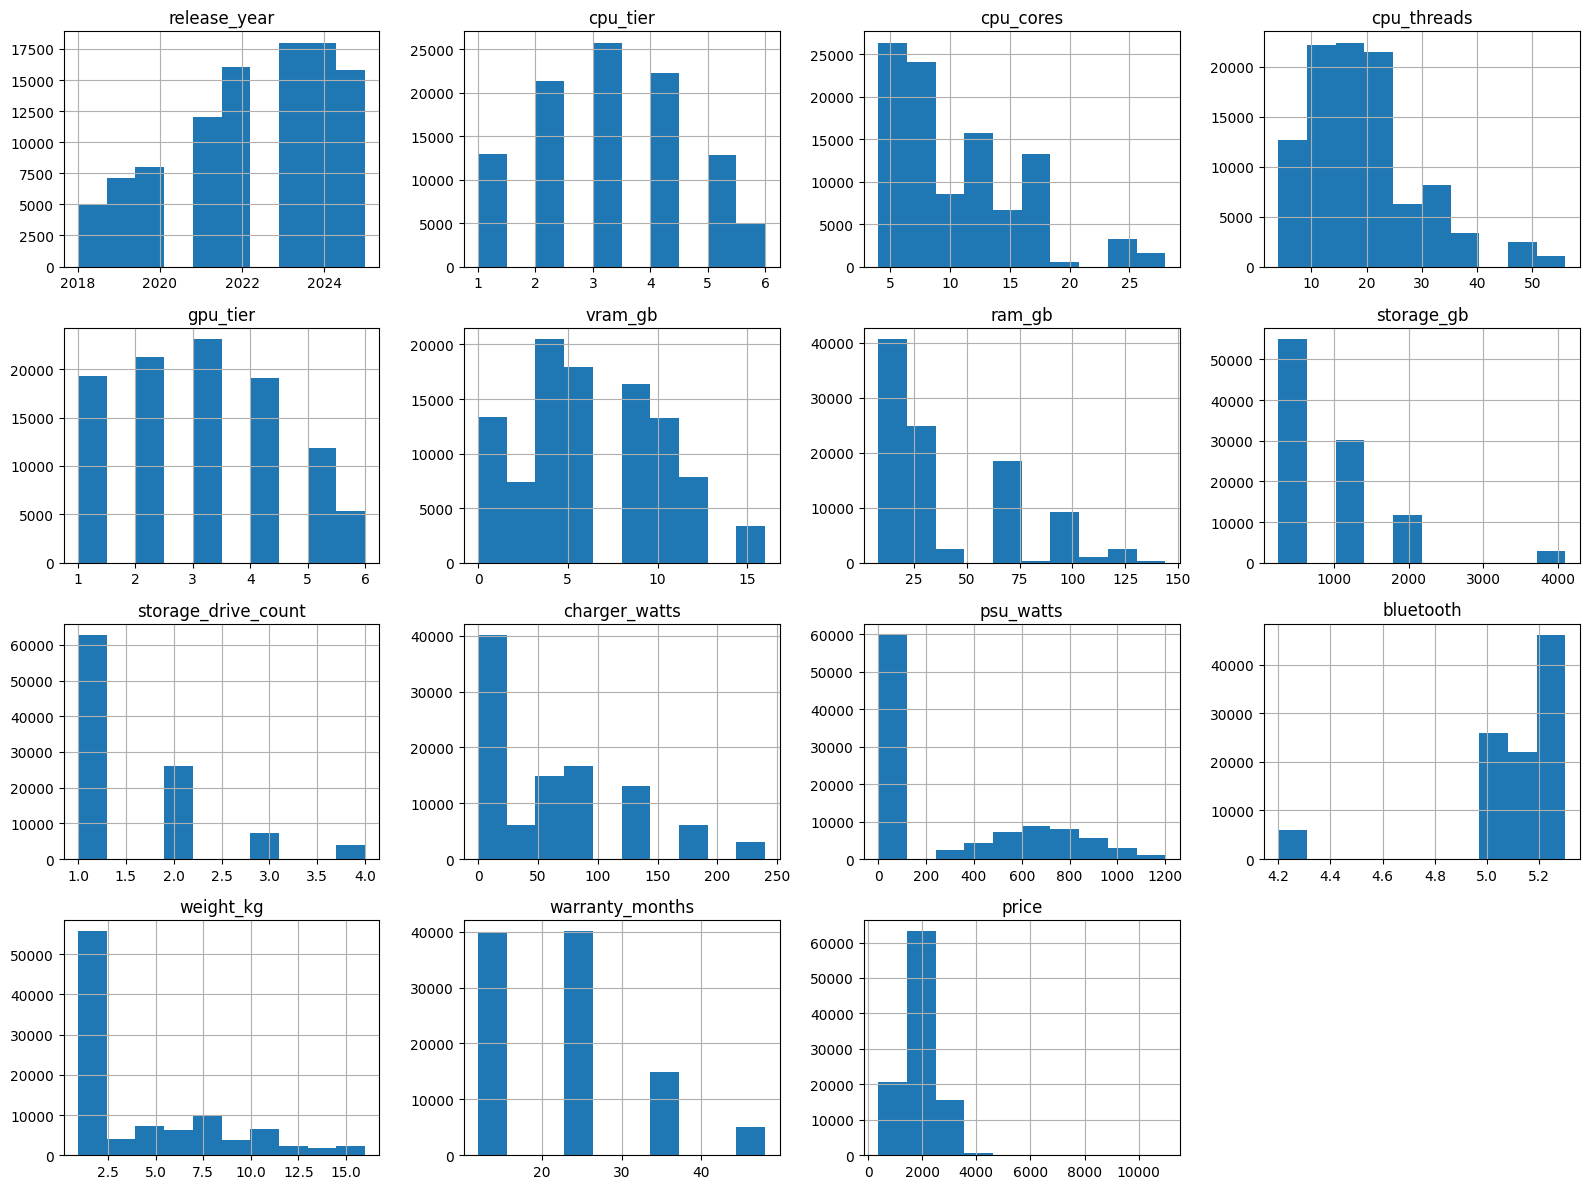

In [540]:
compu_df[num_cols].hist(figsize=(16, 12))
plt.tight_layout()
plt.show()

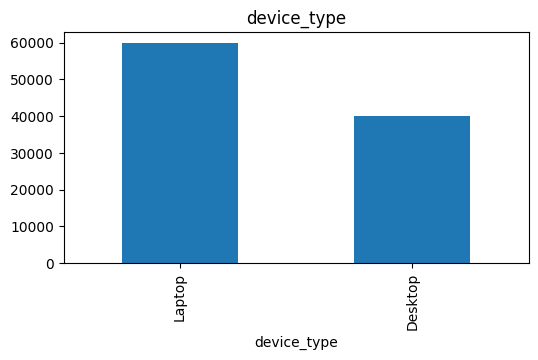

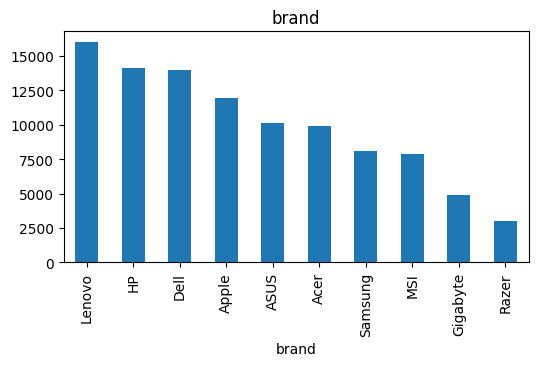

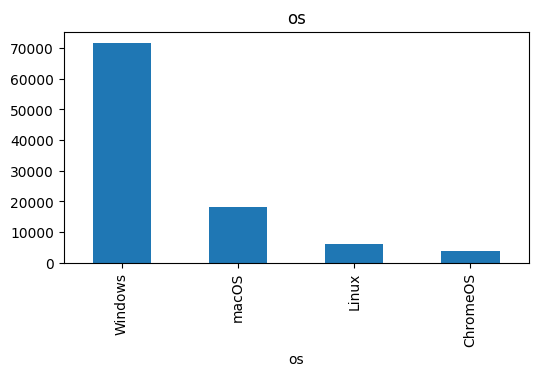

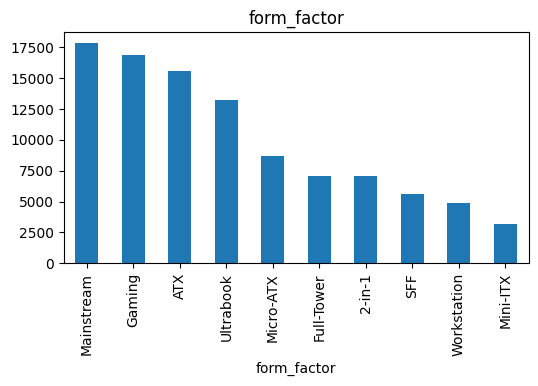

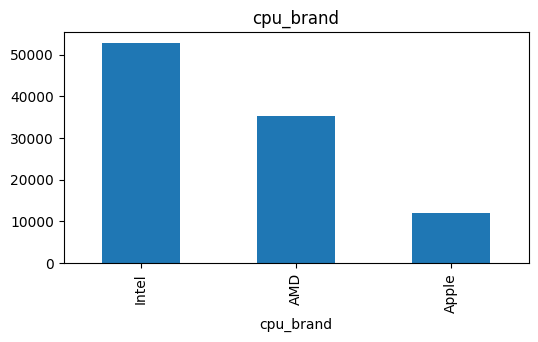

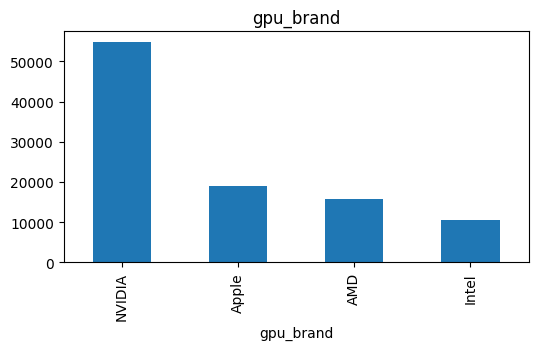

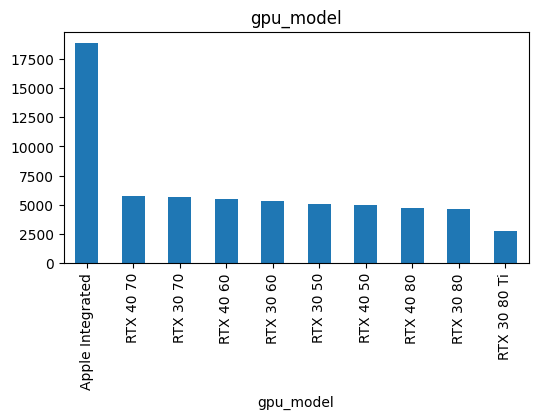

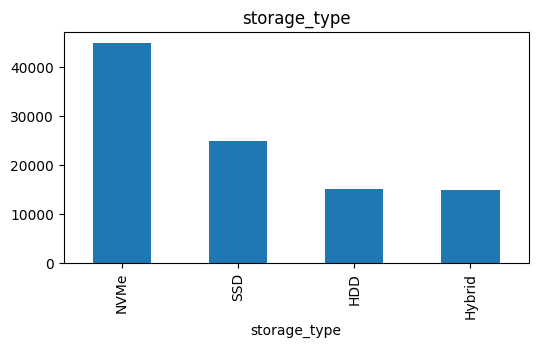

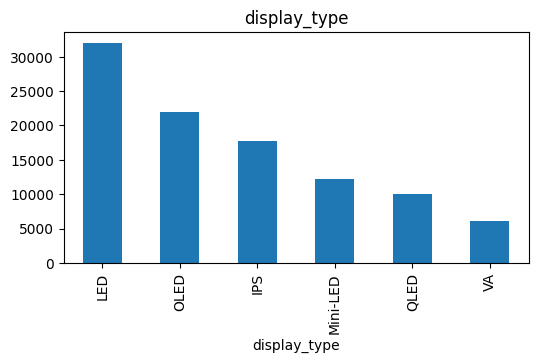

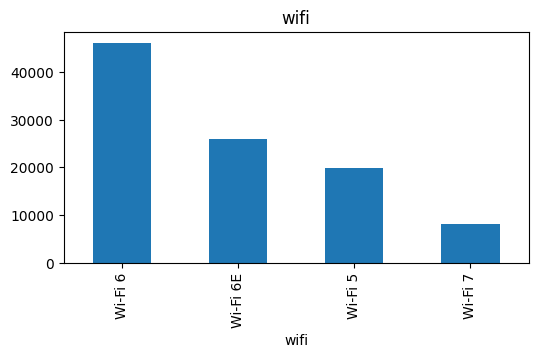

In [541]:
for col in cat_cols:
    compu_df[col].value_counts().head(10).plot(kind='bar', title=col, figsize=(6, 3))
    plt.show()

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.

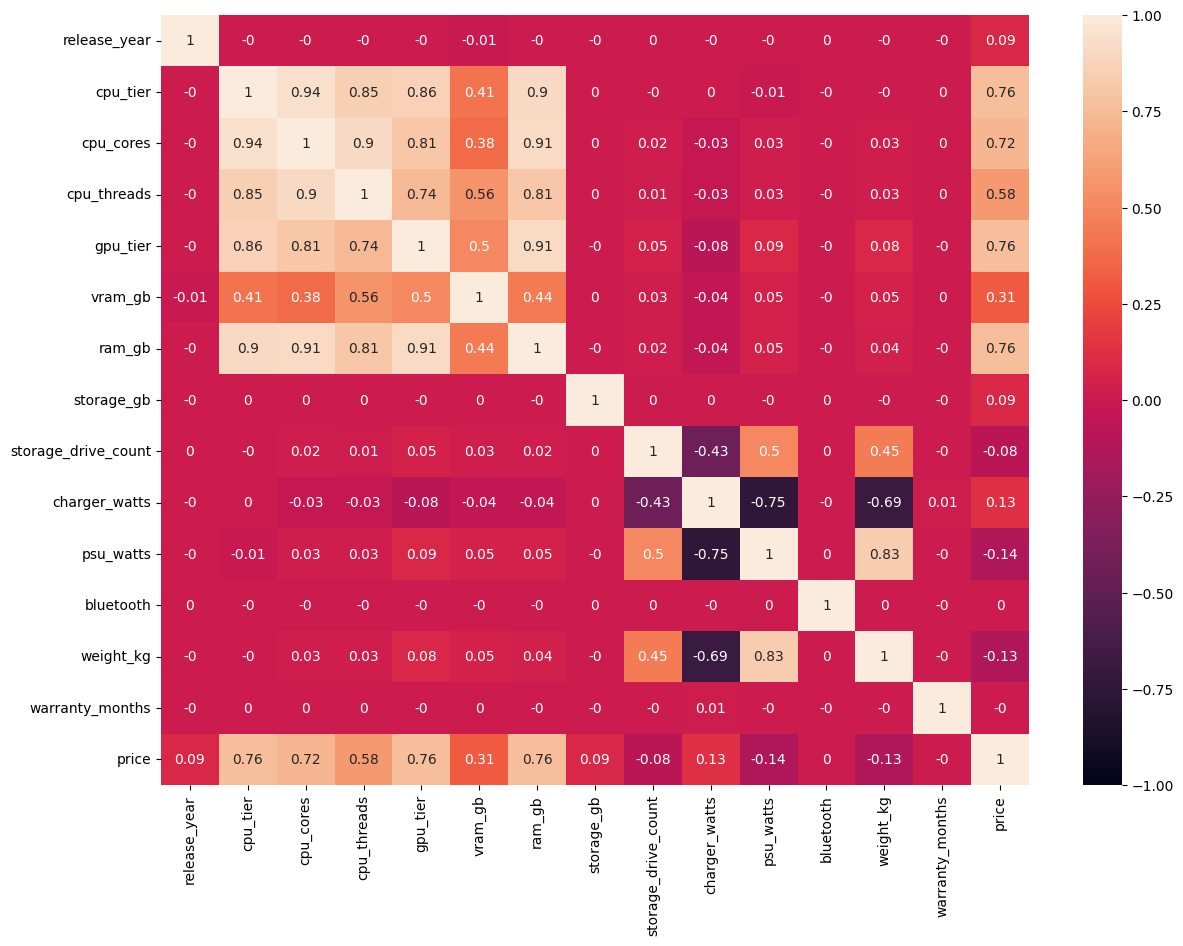

In [542]:
plt.figure(figsize=(14, 10))
corr = compu_df[num_cols].corr()
sns.heatmap(round(corr, 2), annot=True, vmin=-1, vmax=1)
plt.show()

* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.

In [543]:
pares = corr.unstack()
pares = pares[(pares.abs() > 0.9) & (pares < 1)].drop_duplicates()
print(pares)

cpu_tier   cpu_cores    0.937376
cpu_cores  ram_gb       0.906770
gpu_tier   ram_gb       0.912918
dtype: float64


* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.

In [544]:
compu_df = compu_df.drop(columns=['cpu_cores', 'ram_gb'])

compu_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   release_year         100000 non-null  int64  
 3   os                   100000 non-null  object 
 4   form_factor          100000 non-null  object 
 5   cpu_brand            100000 non-null  object 
 6   cpu_tier             100000 non-null  int64  
 7   cpu_threads          100000 non-null  int64  
 8   gpu_brand            100000 non-null  object 
 9   gpu_model            100000 non-null  object 
 10  gpu_tier             100000 non-null  int64  
 11  vram_gb              100000 non-null  int64  
 12  storage_type         100000 non-null  object 
 13  storage_gb           100000 non-null  int64  
 14  storage_drive_count  100000 non-null  int64  
 15  display_type      

* Incluye una breve justificación de tus decisiones.

Se eliminan esas 2 porque se explican con otras variables viendo que hay pares de variables que tienen correlacion > 0.9

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.

In [545]:
compu_transf = compu_df.copy()

* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.

In [546]:
compu_transf['years_since_release'] = date.today().year - compu_transf['release_year']
compu_transf = compu_transf.drop(columns='release_year')
compu_transf['years_since_release'].value_counts().sort_index()

,count
years_since_release,
1,15835
2,17969
3,18020
4,16054
5,12016
6,7986
7,7090
8,5030


* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.

In [547]:
kbins = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
compu_transf[['vram_gb']] = kbins.fit_transform(compu_transf[['vram_gb']])

* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

In [548]:
print('limites de bins:', kbins.bin_edges_[0])


limites de bins: [ 0.  4.  6.  8. 16.]


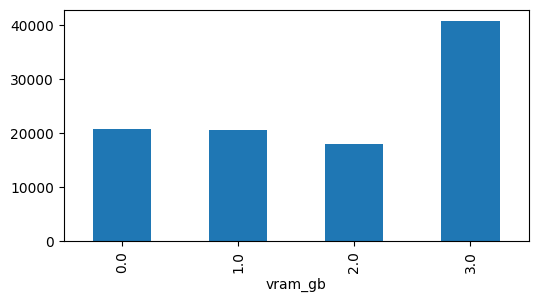

In [549]:
conteo = compu_transf['vram_gb'].value_counts().sort_index()
conteo.plot(kind='bar', figsize=(6, 3))
plt.show()

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.

In [550]:
compu_transf.groupby('device_type')[['charger_watts', 'psu_watts']].agg(['min', 'max'])

charger_watts      psu_watts      
                      min  max       min   max
device_type                                   
Desktop                 0    0       300  1200
Laptop                 45  240         0     0

**Respuesta**: Haciendo un analisis significa que ese atributo no aplica para ese device_type, por ejemplo los desktop no usan charger_watts y las laptops no usan psu_watts

* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.

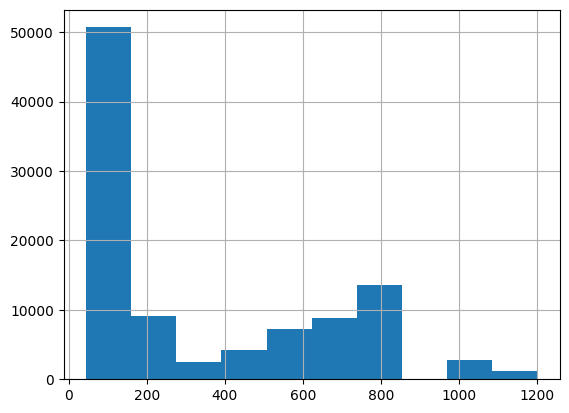

In [551]:
compu_transf['power_watts'] = np.where(compu_transf['device_type'] == 'Laptop',compu_transf['charger_watts'],compu_transf['psu_watts'])

compu_transf['power_watts'].hist()
plt.show()

**Respuesta:** la distribución es bimodal: un pico en potencias bajas (45–240 W, laptops) y otro en potencias altas (300–1200 W, desktops).

* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

In [552]:
compu_transf = compu_transf.drop(columns=['charger_watts', 'psu_watts'])

compu_transf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   os                   100000 non-null  object 
 3   form_factor          100000 non-null  object 
 4   cpu_brand            100000 non-null  object 
 5   cpu_tier             100000 non-null  int64  
 6   cpu_threads          100000 non-null  int64  
 7   gpu_brand            100000 non-null  object 
 8   gpu_model            100000 non-null  object 
 9   gpu_tier             100000 non-null  int64  
 10  vram_gb              100000 non-null  float64
 11  storage_type         100000 non-null  object 
 12  storage_gb           100000 non-null  int64  
 13  storage_drive_count  100000 non-null  int64  
 14  display_type         100000 non-null  object 
 15  wifi              

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.

In [553]:
log_tf = FunctionTransformer(func=np.log, inverse_func=np.exp)
sqrt_tf = FunctionTransformer(func=np.sqrt, inverse_func=np.square)
bc_tf = PowerTransformer(method='box-cox', standardize=False)

* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.

In [554]:
price = compu_transf[['price']]

price_log  = pd.Series(np.ravel(log_tf.fit_transform(price)))
price_sqrt = pd.Series(np.ravel(sqrt_tf.fit_transform(price)))
price_bc   = pd.Series(np.ravel(bc_tf.fit_transform(price)))

* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.

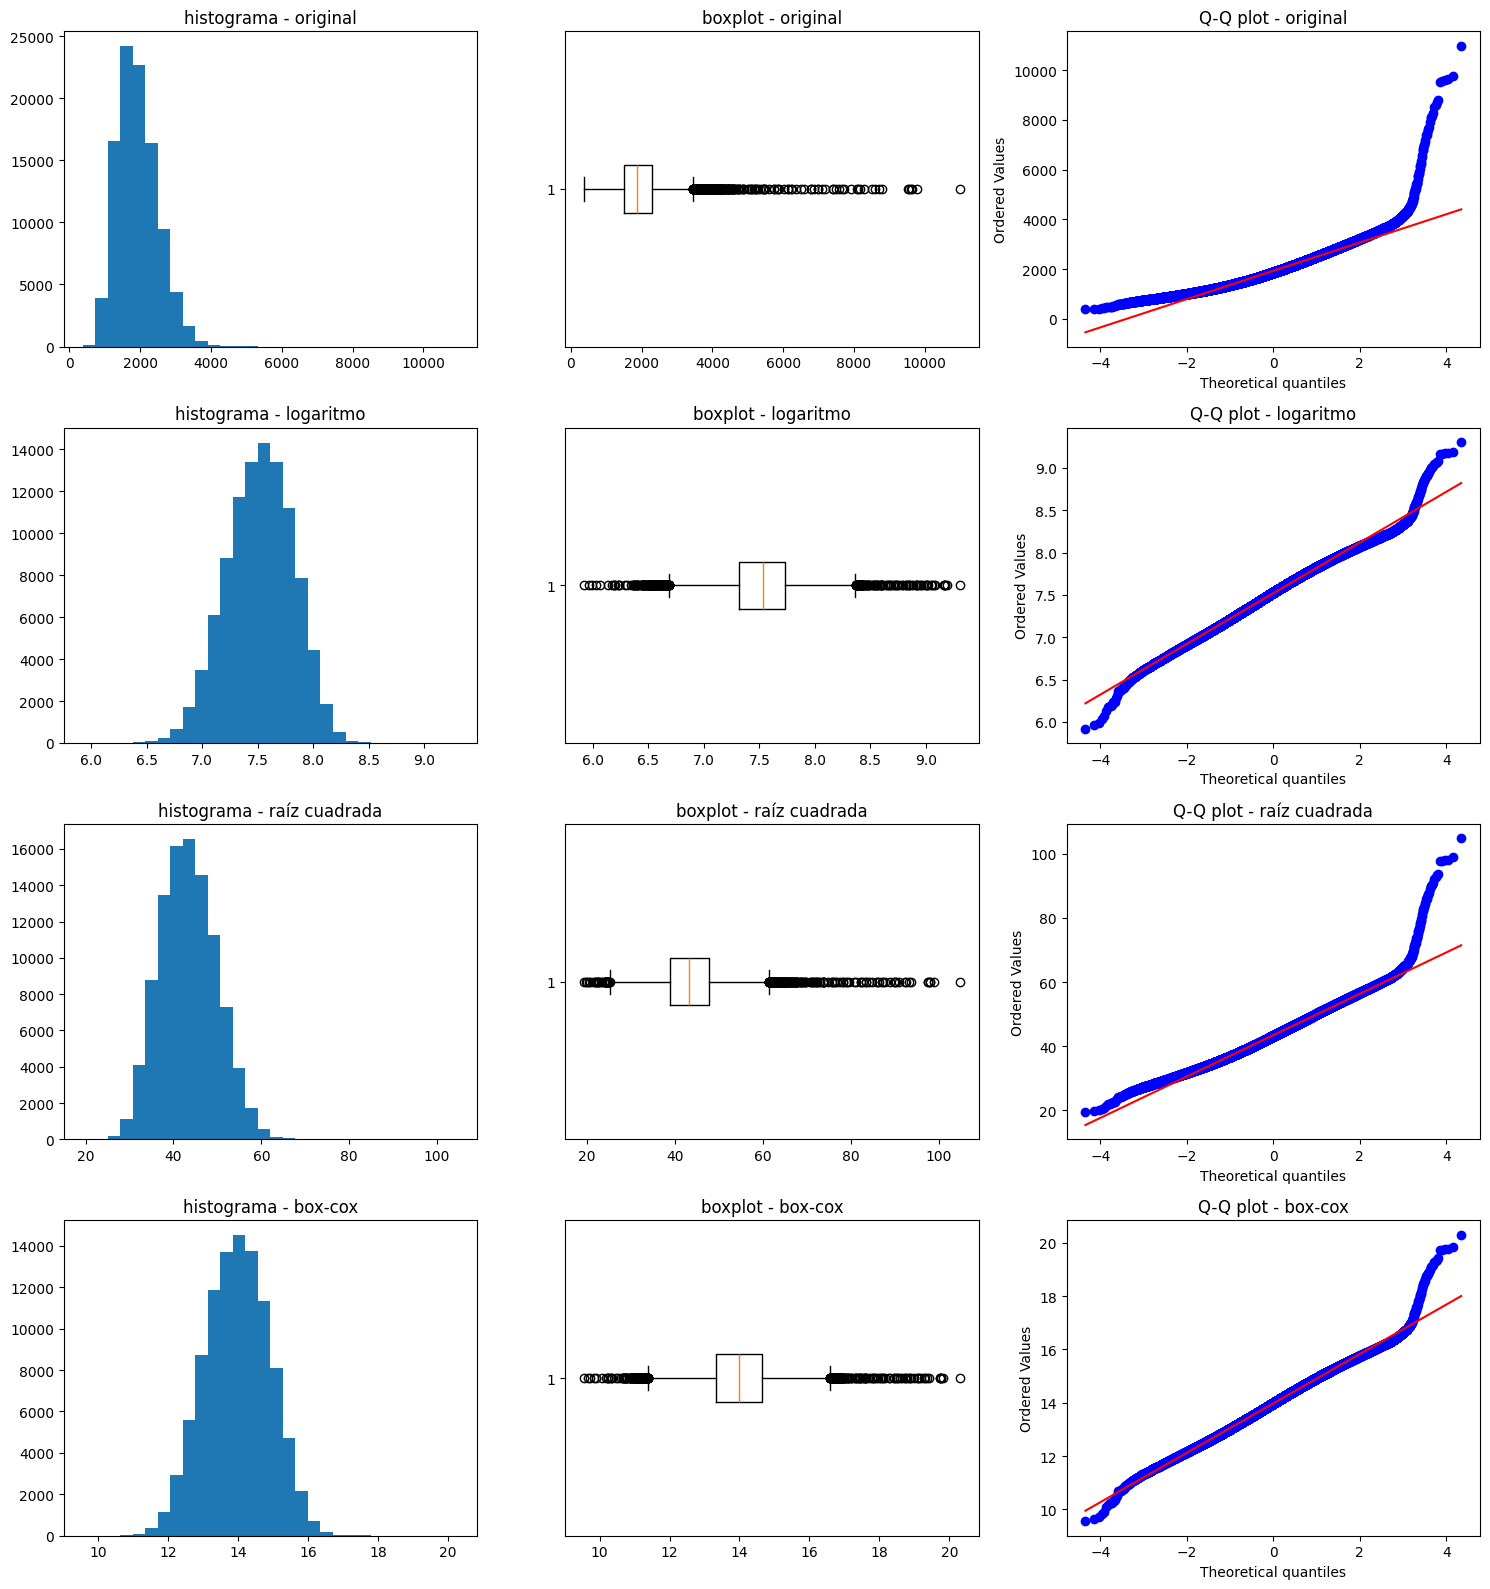

,transformación,skew,outliers
0,original,0.987,976
1,logaritmo,-0.133,386
2,raíz cuadrada,0.332,364
3,box-cox,-0.000,317


In [555]:
versiones = {'original': compu_transf['price'], 'logaritmo': price_log, 'raíz cuadrada': price_sqrt, 'box-cox': price_bc}

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
resumen = []
for i, (nombre, s) in enumerate(versiones.items()):
    #histograma
    axes[i, 0].hist(s, bins=30)
    axes[i, 0].set_title(f'histograma - {nombre}')
    #boxplot
    axes[i, 1].boxplot(s, vert=False)
    axes[i, 1].set_title(f'boxplot - {nombre}')
    #q-q plot
    probplot(s, dist='norm', plot=axes[i, 2])
    axes[i, 2].set_title(f'Q-Q plot - {nombre}')

    # Outliers con el criterio del rango intercuartílico
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    resumen.append([nombre, round(s.skew(), 3), outliers])

plt.tight_layout()
plt.show()

pd.DataFrame(resumen, columns=['transformación', 'skew', 'outliers'])

* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

**Respuesta:** La transformacion Box-Cox logró el mejor resultado: el sesgo pasa de 0.99 a 0 casi, ademas que tienen la menor cantidad de outliers y el histograma es el más simétrico

In [556]:
#aplicando box cox

cont_cols = ['weight_kg', 'power_watts', 'price']
compu_transf[cont_cols] = PowerTransformer(method='box-cox', standardize=False).fit_transform(compu_transf[cont_cols])



7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [557]:
num_cols = compu_transf.select_dtypes(include='number').columns
minmax_scale = MinMaxScaler()
compu_transf[num_cols] = minmax_scale.fit_transform(compu_transf[num_cols])


compu_transf[num_cols].describe().T[['min', 'max']]

,min,max
cpu_tier,0.0,1.0
cpu_threads,0.0,1.0
gpu_tier,0.0,1.0
vram_gb,0.0,1.0
storage_gb,0.0,1.0
storage_drive_count,0.0,1.0
bluetooth,0.0,1.0
weight_kg,0.0,1.0
warranty_months,0.0,1.0
price,0.0,1.0


8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.

In [558]:
ordinal_encoder = OrdinalEncoder(categories=[['Wi-Fi 5', 'Wi-Fi 6', 'Wi-Fi 6E', 'Wi-Fi 7']])
compu_transf[['wifi']] = ordinal_encoder.fit_transform(compu_transf[['wifi']])

compu_transf['wifi'].value_counts()



,count
wifi,
1.0,46149
2.0,25923
0.0,19926
3.0,8002


Se especifica el orden en `categories` porque, por defecto, `OrdinalEncoder` asigna los códigos en orden alfabético y no respetaría la jerarquía real.

* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [559]:
compu_transf[['wifi']] = MinMaxScaler().fit_transform(compu_transf[['wifi']])
compu_transf['wifi'].value_counts()

,count
wifi,
0.333333,46149
0.666667,25923
0.000000,19926
1.000000,8002


9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.

In [560]:
binary_encoder = BinaryEncoder()
bin_result = binary_encoder.fit_transform(compu_transf[['gpu_model']])

bin_result.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   gpu_model_0  100000 non-null  int64
 1   gpu_model_1  100000 non-null  int64
 2   gpu_model_2  100000 non-null  int64
 3   gpu_model_3  100000 non-null  int64
 4   gpu_model_4  100000 non-null  int64
 5   gpu_model_5  100000 non-null  int64
dtypes: int64(6)
memory usage: 4.6 MB


* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [561]:
bin_df = bin_result.copy()
bin_df.head()

,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`

In [562]:
cat_cols = compu_transf.select_dtypes(exclude='number').columns.drop('gpu_model')
print(list(cat_cols))

onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)
onehot_ar = onehot_encoder.fit_transform(compu_transf[cat_cols])
ohe_df = pd.DataFrame(onehot_ar, columns=onehot_encoder.get_feature_names_out(cat_cols),index=compu_transf.index)

['device_type', 'brand', 'os', 'form_factor', 'cpu_brand', 'gpu_brand', 'storage_type', 'display_type']


In [563]:
ohe_df.head()

,device_type_Laptop,brand_Acer,brand_Apple,brand_Dell,brand_Gigabyte,brand_HP,brand_Lenovo,brand_MSI,brand_Razer,brand_Samsung,...,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.

In [564]:
compu_transf = pd.concat([compu_transf.drop(columns=list(cat_cols) + ['gpu_model']),bin_df, ohe_df], axis=1)

In [565]:
compu_transf.head()

,cpu_tier,cpu_threads,gpu_tier,vram_gb,storage_gb,storage_drive_count,wifi,bluetooth,weight_kg,warranty_months,...,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.4,0.384615,0.2,0.666667,0.200000,0.000000,0.333333,0.818182,0.932995,0.666667,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.6,0.384615,0.6,1.000000,0.066667,0.000000,0.333333,1.000000,0.423737,0.000000,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.2,0.230769,0.0,0.333333,0.066667,0.333333,0.333333,0.727273,0.834353,0.333333,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.2,0.153846,0.2,0.666667,0.066667,0.333333,0.333333,0.909091,0.795505,0.666667,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.8,0.538462,0.8,1.000000,0.000000,0.000000,0.333333,0.909091,0.280423,0.000000,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [566]:
compu_transf.describe().T

,count,mean,std,min,25%,50%,75%,max
cpu_tier,100000.0,0.430698,0.274635,0.0,0.200000,0.400000,0.600000,1.0
cpu_threads,100000.0,0.295629,0.186893,0.0,0.153846,0.230769,0.384615,1.0
gpu_tier,100000.0,0.398270,0.291929,0.0,0.200000,0.400000,0.600000,1.0
vram_gb,100000.0,0.595883,0.394170,0.0,0.333333,0.666667,1.000000,1.0
storage_gb,100000.0,0.168733,0.201626,0.0,0.066667,0.066667,0.200000,1.0
storage_drive_count,100000.0,0.174993,0.265761,0.0,0.000000,0.000000,0.333333,1.0
wifi,100000.0,0.406670,0.284834,0.0,0.333333,0.333333,0.666667,1.0
bluetooth,100000.0,0.804331,0.223616,0.0,0.727273,0.818182,0.909091,1.0
weight_kg,100000.0,0.517032,0.293982,0.0,0.280423,0.417162,0.834353,1.0
warranty_months,100000.0,0.283343,0.284219,0.0,0.000000,0.333333,0.333333,1.0


**Respuesta:** el dataframe finalmente tiene todas sus columnas numéricas con valores entre 0 y 1

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude (Claude Haiku 4.5)* [LLM], utilizado para formatear el texto. https://claude.ai/

---